In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# import libraries to perform geocoding
import numpy as np
import rosel.io
import rosel.computation
import rosel.shiroma
import xarray as xr

In [3]:
type, n_jobs, job_memory = ["LOCAL", 16, "8GB"]
client = rosel.computation.create_client(type, n_jobs, job_memory)
client

2025-06-17 15:40:03 [debug    ] <Cluster info: type=LOCAL, n_jobs=16, job_memory=8GB>


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 119.21 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:43611,Workers: 16
Dashboard: http://127.0.0.1:8787/status,Total threads: 16
Started: Just now,Total memory: 119.21 GiB
Comm: tcp://127.0.0.1:40743,Total threads: 1
Dashboard: http://127.0.0.1:42699/status,Memory: 7.45 GiB
Nanny: tcp://127.0.0.1:35247,


In [4]:
in_path = rosel.io.normpath("/home/morea/SENTINEL1/SALZBURG/44")
# path where the coregistered images are stored
slc_path = f"{in_path}/WDIR_DYNAMIC/slcs"
acquisition_date = "2024-10-15"
burst = "iw1_92638"
wdir_path = f"{in_path}/WDIR_STATIC/{burst}"
rtc_ap_path = f"{wdir_path}/radar_grid/rtc_ap"
result_folder = "/home/morea/TEST/RESULTS"

In [5]:
slc = (
    rosel.io.read(slc_path)
    .bursts[burst]
    .orig[acquisition_date]
    .measurements.slc.sel(polarization="V:H")
    .squeeze()
)
A = rosel.io.read(rtc_ap_path, consolidate_metadata=False, mask_and_scale=False).v

In [6]:
slc.shape

(1502, 22898)

In [7]:
A.shape

(1502, 22898)

## Full Resolution

In [8]:
c_gamma = rosel.shiroma.flatten_radar_image(
    slc, A, data_path=f"{result_folder}/flattened_slc", read=True
)

2025-06-17 15:40:06 [debug    ] Selected scatter strategy: once-and-for-all
2025-06-17 15:40:06 [debug    ] Number of blocks to be processed: 46


In [9]:
flattened_intensity = (np.abs(c_gamma) ** 2).to_dataset(name="v")

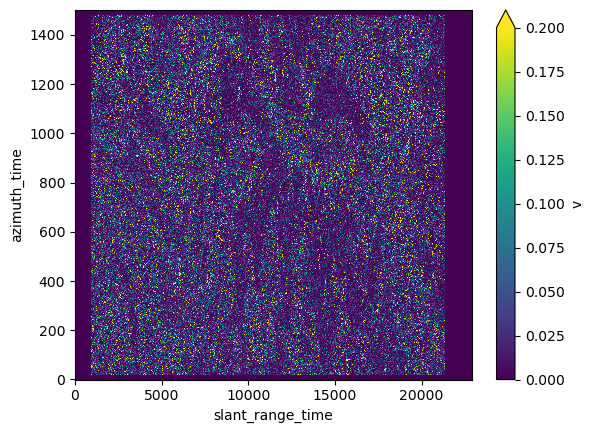

In [10]:
flattened_intensity.v.plot.imshow(vmin=0, vmax=0.2)

In [11]:
rosel.io.write(flattened_intensity, f"{result_folder}/flattened_intensity")

<xarray.Dataset> Size: 138MB
Dimensions:  (azimuth_time: 1502, slant_range_time: 22898)
Dimensions without coordinates: azimuth_time, slant_range_time
Data variables:
    v        (azimuth_time, slant_range_time) float32 138MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
Attributes:
    obj_type:    xr.Dataset
    store_path:  /home/morea/TEST/RESULTS/flattened_intensity

In [12]:
g = rosel.shiroma.map_geo_ap_new(
    c_path=f"{result_folder}/flattened_intensity",
    data_path_shiroma=wdir_path,
    data_path_geo_ap=f"{result_folder}/geo_ap",
    read=True,
    enable_dask=True,
)

2025-06-17 15:40:15 [debug    ] Selected scatter strategy: once-and-for-all
2025-06-17 15:40:15 [debug    ] Number of blocks to be processed: 40


In [13]:
g

<xarray.DataArray 'v' (y: 3539, x: 9836)> Size: 278MB
dask.array<open_dataset-v, shape=(3539, 9836), dtype=complex64, chunksize=(1024, 1024), chunktype=numpy.ndarray>
Coordinates:
    spatial_ref  int64 8B ...
  * x            (x) float64 79kB 2.382e+05 2.382e+05 ... 3.366e+05 3.366e+05
  * y            (y) float64 28kB 5.212e+06 5.212e+06 ... 5.177e+06 5.177e+06
Attributes:
    _FillValue:  0j

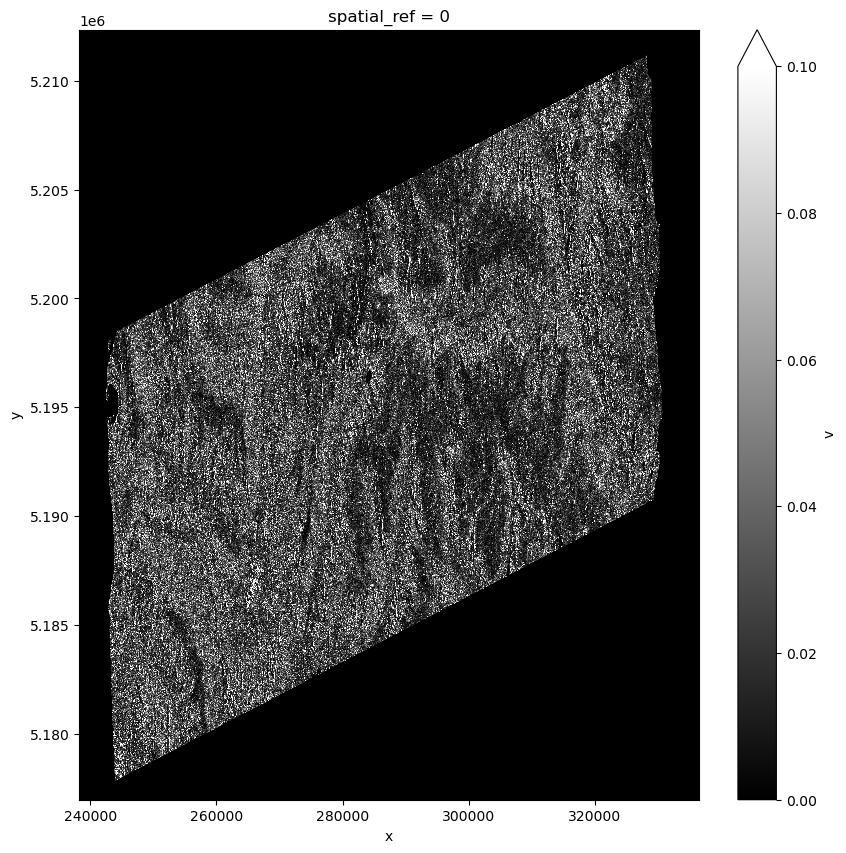

In [27]:
np.real(g).plot.imshow(vmin=0, vmax=0.1, figsize=(10, 10), cmap="gray")

## Multilooked image

In [15]:
multilook = {"azimuth_time": 3, "slant_range_time": 5}

In [16]:
c = np.abs(slc) ** 2

In [17]:
# generating multilooked amplitude
c_ml = (
    c.coarsen(
        azimuth_time=multilook["azimuth_time"],
        slant_range_time=multilook["slant_range_time"],
        boundary="pad",
    )
    .mean()
    .chunk(azimuth_time=300, slant_range_time=300)
)
c_ml = np.sqrt(c_ml)

In [18]:
c_ml

<xarray.DataArray 'slc' (azimuth_time: 501, slant_range_time: 4580)> Size: 9MB
dask.array<sqrt, shape=(501, 4580), dtype=float32, chunksize=(300, 300), chunktype=numpy.ndarray>
Coordinates:
    acquisition_date  <U10 40B '2024-10-15'
    azimuth_m         (azimuth_time) float64 4kB dask.array<chunksize=(300,), meta=np.ndarray>
  * azimuth_time      (azimuth_time) datetime64[ns] 4kB 2024-10-15T16:59:30.2...
    polarization      <U3 12B 'V:H'
    slant_range_m     (slant_range_time) float64 37kB dask.array<chunksize=(300,), meta=np.ndarray>
  * slant_range_time  (slant_range_time) float64 37kB 0.005337 ... 0.005692

In [19]:
c_gamma_ml = rosel.shiroma.flatten_radar_image(
    c_ml,
    A,
    multilook=multilook,
    data_path=f"{result_folder}/flattened_amplitude_ml",
    read=True,
)

2025-06-17 15:40:26 [debug    ] Selected scatter strategy: once-and-for-all
2025-06-17 15:40:27 [debug    ] Number of blocks to be processed: 32


In [20]:
flattened_intensity_ml = (np.abs(c_gamma_ml) ** 2).to_dataset(name="v")

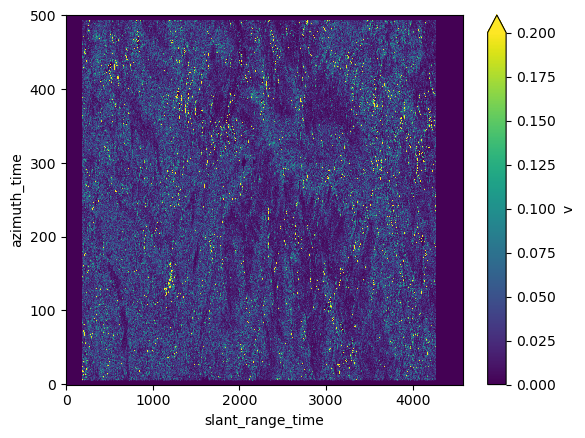

In [21]:
flattened_intensity_ml.v.plot.imshow(vmin=0, vmax=0.2)

In [22]:
rosel.io.write(flattened_intensity_ml, f"{result_folder}/flattened_intensity_ml")

<xarray.Dataset> Size: 9MB
Dimensions:  (azimuth_time: 501, slant_range_time: 4580)
Dimensions without coordinates: azimuth_time, slant_range_time
Data variables:
    v        (azimuth_time, slant_range_time) float32 9MB dask.array<chunksize=(300, 300), meta=np.ndarray>
Attributes:
    obj_type:    xr.Dataset
    store_path:  /home/morea/TEST/RESULTS/flattened_intensity_ml

In [23]:
g_ml = rosel.shiroma.map_geo_ap_new(
    c_path=f"{result_folder}/flattened_intensity_ml",
    data_path_shiroma=wdir_path,
    data_path_geo_ap=f"{result_folder}/geo_ap_ml",
    multilook=multilook,
    read=True,
    enable_dask=True,
)

2025-06-17 15:40:29 [debug    ] Selected scatter strategy: once-and-for-all
2025-06-17 15:40:29 [debug    ] Number of blocks to be processed: 40


In [24]:
g_ml.max().values, g_ml.min().values

(array(69.05955+0.j, dtype=complex64), array(0.+0.j, dtype=complex64))

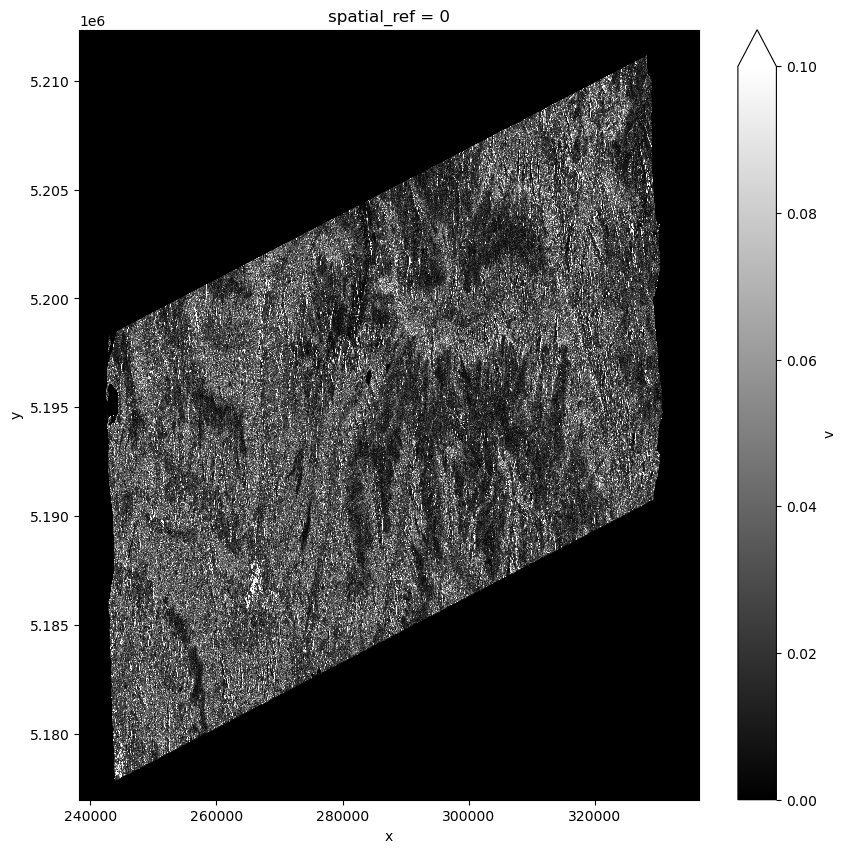

In [28]:
np.real(g_ml).plot.imshow(vmin=0, vmax=0.1, figsize=(10, 10), cmap="gray")

In [42]:
g.rio.crs

CRS.from_wkt('PROJCRS["WGS 84 / UTM zone 33N",BASEGEOGCRS["WGS 84",ENSEMBLE["World Geodetic System 1984 ensemble",MEMBER["World Geodetic System 1984 (Transit)"],MEMBER["World Geodetic System 1984 (G730)"],MEMBER["World Geodetic System 1984 (G873)"],MEMBER["World Geodetic System 1984 (G1150)"],MEMBER["World Geodetic System 1984 (G1674)"],MEMBER["World Geodetic System 1984 (G1762)"],MEMBER["World Geodetic System 1984 (G2139)"],MEMBER["World Geodetic System 1984 (G2296)"],ELLIPSOID["WGS 84",6378137,298.257223563,LENGTHUNIT["metre",1]],ENSEMBLEACCURACY[2.0]],PRIMEM["Greenwich",0,ANGLEUNIT["degree",0.0174532925199433]],ID["EPSG",4979]],CONVERSION["UTM zone 33N",METHOD["Transverse Mercator",ID["EPSG",9807]],PARAMETER["Latitude of natural origin",0,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8801]],PARAMETER["Longitude of natural origin",15,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8802]],PARAMETER["Scale factor at natural origin",0.9996,SCALEUNIT["unity",1],ID["EPSG",8805]],PARAM

In [35]:
def to_raster(data, path, driver):
    from pyproj import CRS

    crs = CRS(g.rio.crs).to_2d().to_epsg()
    data.rio.write_crs(crs).rio.to_raster(path, driver=driver)
    return

In [37]:
np.real(g).rio.to_raster("/home/morea/RASTERS/test_original.tiff", driver="COG")

In [36]:
to_raster(np.real(g), "/home/morea/RASTERS/test.tiff", driver="COG")